# ⚖️ EVALUASI PERBANDINGAN — XGBoost vs LSTM
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🎯 Tujuan (menjawab RM-3)
Membandingkan performa **XGBoost** (tabular/non-sequential) dan **LSTM** (sequential, lookback=10)
secara **adil** untuk memprediksi volatilitas return saham harian.

### 🔧 Perbaikan metodologis dibanding notebook sebelumnya
1. **Skala identik** — kedua model dievaluasi pada **skala volatilitas asli** (inverse-transform MinMax
   diterapkan ke *kedua* model, termasuk XGBoost yang sebelumnya terlewat).
2. **Sampel uji selaras** — XGBoost dievaluasi hanya pada baris `[lookback:]` agar **titik target persis sama**
   dengan LSTM (LSTM kehilangan `lookback` baris pertama karena windowing).
3. **Metrik diperluas** — selain RMSE, MAE, MAPE, ditambahkan **sMAPE, R², dan QLIKE**
   yang lebih sesuai untuk peramalan volatilitas.
4. **Reprodusibel** — notebook berdiri sendiri (load model `.pkl` & `.keras` yang sudah disimpan).

### 📥 Input
- `dataset_test_{emiten}.csv`, `scaler_params_{emiten}.csv`  (per emiten, sudah ter-scale)
- Model tersimpan: `xgboost_{emiten}.pkl`, `lstm_best_{emiten}.keras`

### 📤 Output (→ Bab 4 Tesis)
- `tabel_perbandingan_xgb_lstm.csv` (Tabel 4.X)
- `gambar_perbandingan_xgb_lstm.png` (Gambar 4.X)
- Kesimpulan model terbaik per emiten & keseluruhan


In [2]:
import os, datetime
from pathlib import Path
import pandas as pd

# ════════════════════════════════════════════════════════════════════
#  PATH KANONIK + IO UTILITAS — IDENTIK DI SEMUA NOTEBOOK
#  (otomatis disisipkan oleh proses audit path)
# ════════════════════════════════════════════════════════════════════
ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT = cari_root()
DIR_RAW       = ROOT / '03_dataset' / 'raw'
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_MODEL     = ROOT / '04_model'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
for _d in (DIR_RAW, DIR_PROCESSED, DIR_FINAL, DIR_TABEL):
    _d.mkdir(parents=True, exist_ok=True)

# Nama file kanonik
F_HARGA    = 'harga_saham_raw.csv'         # DIR_RAW
F_TEKNIKAL = 'technical_features.csv'      # DIR_PROCESSED (satu-satunya lokasi)
F_SENTIMEN = 'skor_sentimen_harian.csv'    # DIR_PROCESSED (nama tunggal)
F_GABUNGAN = 'dataset_gabungan_X1X2Y.csv'  # DIR_FINAL

def muat_csv(path, **kw):
    """LOAD + log sumber absolut. Error eksplisit bila tak ada (TANPA fallback diam-diam)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}\n'
                                f'   -> Tahap sebelumnya belum menyimpan ke lokasi kanonik ini.')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

def simpan_csv(df, path, index=False, **kw):
    """SAVE + log path absolut + WARNING bila menimpa file lama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        mt = datetime.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        print(f'OVERWRITE: {path.resolve()}  (file lama {mt} ditimpa)')
    df.to_csv(path, index=index, encoding='utf-8-sig', **kw)
    print(f'SAVE  : {path.resolve()}  ({len(df):,} baris)')

print(f'ROOT : {ROOT.resolve()}')
print(f'  RAW={DIR_RAW.name}/  PROCESSED={DIR_PROCESSED.name}/  FINAL={DIR_FINAL.name}/')


ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  RAW=raw/  PROCESSED=processed/  FINAL=final/


## ⚙️ CELL 1 — Import & Konfigurasi

In [3]:
import warnings, os
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow import keras

# ============================================================
# KONFIGURASI — sesuaikan ROOT bila lokasi folder berbeda
# ============================================================
ROOT = Path(r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
            r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')
if not ROOT.exists():
    ROOT = Path('.').resolve()          # fallback: jalankan dari folder proyek

DIR_FINAL   = ROOT / '03_dataset' / 'final'
DIR_XGB     = ROOT / '04_model' / 'xgboost'
DIR_LSTM    = ROOT / '04_model' / 'lstm'
DIR_TABEL   = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR  = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
# FIX AUDIT — sama seperti notebook training: harus target FORECAST (t+1)
KOLOM_Y       = 'Volatilitas_Target'
# FIX v3: LOOKBACK tidak lagi konstanta. CELL 4B (tuning) MODEL_lstm_v4
# menghasilkan lookback BERBEDA per emiten; memakai 10 untuk semua akan
# membentuk sekuens yang tidak sama dengan saat training -> metrik salah.
LOOKBACK_DEFAULT = 10
def _muat_lookback_map():
    p = ROOT / '06_dokumen_tesis' / 'tabel' / 'tabel_hyperparameter_lstm.csv'
    peta = {e: LOOKBACK_DEFAULT for e in URUTAN_EMITEN}
    if not p.exists():
        print(f'  ⚠️  {p.name} tidak ada -> pakai lookback {LOOKBACK_DEFAULT} untuk semua.')
        return peta
    d = pd.read_csv(p)
    kol_e = next((c for c in d.columns if c.lower() in ('emiten','kode_emiten')), None)
    kol_l = next((c for c in d.columns if 'lookback' in c.lower()), None)
    if kol_e and kol_l:
        for _, r in d.iterrows():
            if r[kol_e] in peta:
                peta[r[kol_e]] = int(r[kol_l])
        print(f'  ℹ️  Lookback per emiten dari {p.name}: {peta}')
    else:
        print(f'  ⚠️  Kolom emiten/lookback tak ditemukan -> pakai {LOOKBACK_DEFAULT}.')
    return peta
LOOKBACK_MAP = _muat_lookback_map()
LOOKBACK     = LOOKBACK_DEFAULT   # dipertahankan hanya utk kompatibilitas
EPS           = 1e-8

# Daftar fitur X (21). Biarkan None untuk auto-derive dari CSV (semua kolom
# kecuali kolom non-fitur). Jika urutan fitur saat training berbeda, ISI manual
# dengan KOLOM_X_KANDIDAT asli Anda agar urutan fitur identik dgn saat training.
# FIX AUDIT — diselaraskan PERSIS dgn KOLOM_X_KANDIDAT di MODEL_xgboost_v2 /
# MODEL_lstm_v2 (17 fitur: 13 X1 + 4 X2). Kalau model tersimpan punya
# feature_names_in_/input_shape sendiri, CELL 4/5 akan otomatis
# menyelaraskan lebih lanjut — tapi baseline ini harus benar dari awal.
KOLOM_X_MANUAL = [
    # X1 Teknikal (13)
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
    # X2 Sentimen (4)
    'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita',
]
KOLOM_NON_FITUR = {'Date', 'Emiten', KOLOM_Y, 'No', 'Unnamed: 0'}

print('='*65)
print('  ⚖️  EVALUASI PERBANDINGAN — SIAP DIJALANKAN')
print('='*65)
print(f'  ROOT        : {ROOT}')
print(f'  TensorFlow  : {tf.__version__}')
print(f'  Emiten      : {URUTAN_EMITEN}')
print(f'  Lookback    : {LOOKBACK}  | Target Y : {KOLOM_Y}')


  ℹ️  Lookback per emiten dari tabel_hyperparameter_lstm.csv: {'ADRO': 10, 'ADMR': 10, 'ITMG': 15, 'PTBA': 10, 'MEDC': 10, 'AKRA': 15, 'PGAS': 15}
  ⚖️  EVALUASI PERBANDINGAN — SIAP DIJALANKAN
  ROOT        : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  TensorFlow  : 2.21.0
  Emiten      : ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
  Lookback    : 10  | Target Y : Volatilitas_Target


## 🔧 CELL 2 — Fungsi Bantu: Metrik, Inverse-Transform, Sekuens

In [4]:
def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    '''Kembalikan nilai ter-MinMax-scale ke skala asli. Identik dgn notebook LSTM.'''
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min'])
    cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai, dtype=float) * (cmax - cmin) + cmin

def inverse_lstm(nilai_log):
    '''FIX v3 — KRITIS. MODEL_lstm_v4 dilatih pada LOG-TARGET: keluaran model
    adalah log(volatilitas), BUKAN nilai ter-MinMax-scale. Karena itu
    pengembalian ke skala asli memakai eksponensial, bukan inverse MinMax.
    Memakai inverse_transform() di sini menghasilkan angka yang sepenuhnya
    keliru (tanpa pesan error apa pun).'''
    return np.exp(np.asarray(nilai_log, dtype=float))

def buat_sekuens(X, y, lookback=LOOKBACK):
    '''Windowing untuk LSTM. Output y selaras dgn y[lookback:].'''
    Xs, ys = [], []
    for t in range(lookback, len(X)):
        Xs.append(X[t-lookback:t, :]); ys.append(y[t])
    return np.array(Xs), np.array(ys)

# ---------- Metrik (skala asli) ----------
def hitung_mape(y_true, y_pred, eps=EPS):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    mask = np.abs(y_true) > eps
    return np.nan if mask.sum() == 0 else \
        float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def hitung_smape(y_true, y_pred, eps=EPS):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    den = np.abs(y_true) + np.abs(y_pred); mask = den > eps
    return np.nan if mask.sum() == 0 else \
        float(np.mean(2*np.abs(y_pred[mask]-y_true[mask])/den[mask])*100)

def hitung_qlike(y_true, y_pred, eps=1e-12):
    '''QLIKE (Patton, 2011) pada proksi varians h = vol^2. Makin kecil makin baik.'''
    h_t = np.maximum(np.asarray(y_true, float)**2, eps)
    h_p = np.maximum(np.asarray(y_pred, float)**2, eps)
    return float(np.mean(np.log(h_p) + h_t/h_p))

def evaluasi_semua_metrik(y_true, y_pred):
    return {
        'RMSE' : float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE'  : float(mean_absolute_error(y_true, y_pred)),
        'MAPE (%)'  : round(hitung_mape(y_true, y_pred), 2),
        'sMAPE (%)' : round(hitung_smape(y_true, y_pred), 2),
        'R2'   : round(float(r2_score(y_true, y_pred)), 4),
        'QLIKE': round(hitung_qlike(y_true, y_pred), 4),
    }

print('✅ Fungsi bantu siap.')


✅ Fungsi bantu siap.


## 📂 CELL 3 — Load Data Uji, Scaler, dan Daftar Fitur per Emiten

In [5]:
dict_train, dict_test, dict_scaler, dict_kolom_x = {}, {}, {}, {}

for emiten in URUTAN_EMITEN:
    path_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    path_te = DIR_FINAL / f'dataset_test_{emiten}.csv'
    path_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'
    if not path_te.exists():
        print(f'  \u26a0\ufe0f  {emiten}: dataset_test tidak ditemukan, skip'); continue

    df_te = muat_csv(path_te, encoding='utf-8-sig')
    df_tr = muat_csv(path_tr, encoding='utf-8-sig') if path_tr.exists() else None
    for d in (df_tr, df_te):
        if d is not None and 'Date' in d.columns:
            d['Date'] = pd.to_datetime(d['Date'], errors='coerce')

    # \u2500\u2500 Tentukan fitur X (sumber kebenaran = DATA LATIH) \u2500\u2500
    #    Hindari denylist pd data test: test kadang punya kolom ekstra
    #    (mis. OHLCV mentah) yg tak dilihat model \u2192 mismatch jumlah fitur.
    if KOLOM_X_MANUAL is not None:
        sumber = list(KOLOM_X_MANUAL)                                   # allowlist eksplisit
    elif df_tr is not None:
        sumber = [c for c in df_tr.columns if c not in KOLOM_NON_FITUR] # urutan training
    else:
        sumber = [c for c in df_te.columns if c not in KOLOM_NON_FITUR]

    # Hanya pakai kolom yg ADA di train (bila ada) DAN test
    kolom_x = [c for c in sumber
               if c in df_te.columns and (df_tr is None or c in df_tr.columns)]

    df_te = df_te.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    if df_tr is not None:
        df_tr = df_tr.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)

    scaler = pd.read_csv(path_sc, index_col=0, encoding='utf-8-sig') if path_sc.exists() else None

    dict_train[emiten]   = df_tr
    dict_test[emiten]    = df_te
    dict_scaler[emiten]  = scaler
    dict_kolom_x[emiten] = kolom_x

    extra_test = [c for c in df_te.columns
                  if c not in KOLOM_NON_FITUR and c not in kolom_x]
    info_extra = f' | kolom test diabaikan: {len(extra_test)}' if extra_test else ''
    print(f'  \u2705 {emiten}: test={len(df_te):,} | fitur={len(kolom_x)} | '
          f'scaler={"ada" if scaler is not None else "TIDAK ADA"}{info_extra}')

print(f'\n  Total emiten dimuat: {len(dict_test)}')
print('  \u2139\ufe0f  Jika "fitur" \u2260 jumlah fitur saat melatih model, isi KOLOM_X_MANUAL di Cell 1.')


LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_test_ADRO.csv  (209 baris x 20 kolom)
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_train_ADRO.csv  (832 baris x 20 kolom)
  ✅ ADRO: test=209 | fitur=17 | scaler=ada
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_test_ADMR.csv  (209 baris x 20 kolom)
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_train_ADMR.csv  (832 baris x 20 kolom)
  ✅ ADMR: test=209 | fitur=17 | scaler=ada
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\

## 🌳 CELL 4 — Evaluasi XGBoost (skala asli, sampel selaras)
> **Perbaikan kunci:** prediksi di-*inverse-transform* ke skala volatilitas asli, lalu
> dipotong ke baris `[LOOKBACK:]` agar titik ujinya **identik** dengan LSTM.

In [6]:
hasil_xgb = {}

def _scaler_bisa_inverse(scaler_df, kolom=KOLOM_Y):
    """True jika scaler valid utk inverse-transform kolom target (ada index + kolom min/max)."""
    return (scaler_df is not None
            and kolom in scaler_df.index
            and {'min', 'max'}.issubset(set(scaler_df.columns)))

for emiten in URUTAN_EMITEN:
    if emiten not in dict_test:
        continue
    path_mdl = DIR_XGB / f'xgboost_{emiten}.pkl'
    if not path_mdl.exists():
        print(f'  \u26a0\ufe0f  {emiten}: model XGBoost tidak ditemukan, skip'); continue

    model   = joblib.load(path_mdl)
    df_te   = dict_test[emiten]
    kolom_x = list(dict_kolom_x[emiten])
    scaler  = dict_scaler[emiten]

    # \u2500\u2500 Samakan urutan fitur dgn saat training bila model menyimpan nama fitur
    if hasattr(model, 'feature_names_in_'):
        nama_model = list(model.feature_names_in_)
        if set(nama_model).issubset(set(df_te.columns)):
            kolom_x = nama_model
        else:
            print(f'  \u26a0\ufe0f  {emiten}: nama fitur model tidak cocok dgn kolom data.')

    # \u2500\u2500 Validasi jumlah fitur \u2014 SKIP (bukan crash) bila tak cocok
    n_exp = getattr(model, 'n_features_in_', None)
    if n_exp is not None and n_exp != len(kolom_x):
        print(f'  \u274c {emiten}: jumlah fitur tidak cocok \u2014 model butuh {n_exp}, '
              f'tersedia {len(kolom_x)}. Emiten di-SKIP.\n'
              f'      \u2192 Solusi: set KOLOM_X_MANUAL (Cell 1) dgn {n_exp} nama fitur '
              f'persis spt saat melatih model, lalu jalankan ulang Cell 3 & 4.')
        continue

    # \u2500\u2500 Peringatan keras bila scaler tak bisa inverse-transform
    if not _scaler_bisa_inverse(scaler):
        print(f'  \u2757 {emiten}: scaler TIDAK valid utk "{KOLOM_Y}" (min/max tak ditemukan). '
              f'Metrik akan pada SKALA SCALED, tidak sebanding dgn LSTM \u2014 cek scaler_params_{emiten}.csv.')

    X_te        = df_te[kolom_x].values
    y_te_scaled = df_te[KOLOM_Y].values
    try:
        # FIX v3: '/100' DIHAPUS. Trik mengalikan target x100 (MODEL_xgboost_v2
        # CELL 5) sudah dibuang di MODEL_xgboost_v3 karena mendistorsi gamma &
        # reg_lambda yang bersifat relatif terhadap skala loss. Membagi 100 di
        # sini akan membuat prediksi 100x terlalu kecil.
        y_pred_scaled = model.predict(X_te)
    except Exception as e:
        print(f'  \u274c {emiten}: gagal prediksi ({type(e).__name__}: {e}). Emiten di-SKIP.')
        continue

    # \u2500\u2500 Selaraskan dgn LSTM: buang _lb baris pertama (FIX v3: lookback per emiten)
    _lb = LOOKBACK_MAP.get(emiten, LOOKBACK_DEFAULT)
    if len(y_te_scaled) <= _lb:
        print(f'  \u26a0\ufe0f  {emiten}: data uji ({len(y_te_scaled)}) <= lookback ({_lb}), skip')
        continue
    y_te_scaled   = y_te_scaled[_lb:]
    y_pred_scaled = y_pred_scaled[_lb:]
    dates = (df_te['Date'].iloc[_lb:].reset_index(drop=True)
             if 'Date' in df_te.columns else None)

    # \u2500\u2500 Inverse-transform ke skala volatilitas asli
    y_true = inverse_transform(y_te_scaled,   scaler)
    y_pred = np.clip(inverse_transform(y_pred_scaled, scaler), 0, None)

    # \u2500\u2500 Buang pasangan NaN/inf (dan jaga keselarasan dates)
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    if valid.sum() == 0:
        print(f'  \u26a0\ufe0f  {emiten}: seluruh nilai NaN/inf, skip'); continue
    y_true, y_pred = y_true[valid], y_pred[valid]
    if dates is not None:
        dates = dates[valid].reset_index(drop=True)

    metrik = evaluasi_semua_metrik(y_true, y_pred)
    hasil_xgb[emiten] = {'y_true': y_true, 'y_pred': y_pred, 'dates': dates, **metrik}
    print(f"  \u2705 {emiten}: RMSE={metrik['RMSE']:.5f} | MAE={metrik['MAE']:.5f} | "
          f"MAPE={metrik['MAPE (%)']:.2f}% | R2={metrik['R2']}")

print(f'\n  XGBoost dievaluasi: {len(hasil_xgb)} emiten')


  ✅ ADRO: RMSE=1.64067 | MAE=1.50680 | MAPE=6008.91% | R2=-63144.2582
  ✅ ADMR: RMSE=3.01349 | MAE=2.70124 | MAPE=6970.32% | R2=-43356.1099
  ✅ ITMG: RMSE=1.35990 | MAE=1.00115 | MAPE=5480.71% | R2=-18884.6114
  ✅ PTBA: RMSE=1.15948 | MAE=0.90769 | MAPE=4797.85% | R2=-19824.0957
  ✅ MEDC: RMSE=2.12877 | MAE=1.93836 | MAPE=5910.75% | R2=-46314.1102
  ✅ AKRA: RMSE=1.58423 | MAE=1.47370 | MAPE=5966.58% | R2=-72060.0711
  ✅ PGAS: RMSE=1.35024 | MAE=1.23877 | MAPE=5868.38% | R2=-27506.1867

  XGBoost dievaluasi: 7 emiten


## 🧠 CELL 5 — Evaluasi LSTM (skala asli)

In [7]:
hasil_lstm = {}

for emiten in URUTAN_EMITEN:
    if emiten not in dict_test:
        continue
    path_mdl = DIR_LSTM / f'lstm_best_{emiten}.keras'
    if not path_mdl.exists():
        print(f'  ⚠️  {emiten}: model LSTM tidak ditemukan, skip'); continue

    model   = keras.models.load_model(path_mdl, compile=False)
    df_te   = dict_test[emiten]
    kolom_x = dict_kolom_x[emiten]
    scaler  = dict_scaler[emiten]

    X_te = df_te[kolom_x].values.astype(float)
    y_te = df_te[KOLOM_Y].values.astype(float)
    _lb = LOOKBACK_MAP.get(emiten, LOOKBACK_DEFAULT)   # FIX v3: per emiten
    X_seq, y_seq = buat_sekuens(X_te, y_te, _lb)

    # Validasi bentuk input
    n_exp = model.input_shape[-1]
    if n_exp != X_seq.shape[-1]:
        print(f'  ❌ {emiten}: fitur LSTM ({X_seq.shape[-1]}) != input model ({n_exp}). '
              f'Emiten di-SKIP — set KOLOM_X_MANUAL agar konsisten.'); continue

    y_pred_scaled = model.predict(X_seq, verbose=0).flatten()
    dates = df_te['Date'].iloc[_lb:].reset_index(drop=True) if 'Date' in df_te.columns else None

    y_true = inverse_transform(y_seq,        scaler)
    # FIX v3 KRITIS: keluaran LSTM v4 = LOG volatilitas -> pakai exp(),
    # BUKAN inverse MinMax. (y_true tetap inverse MinMax karena dibaca
    # dari CSV yang memang ter-scale.)
    y_pred = np.clip(inverse_lstm(y_pred_scaled), 0, None)

    metrik = evaluasi_semua_metrik(y_true, y_pred)
    hasil_lstm[emiten] = {'y_true': y_true, 'y_pred': y_pred, 'dates': dates, **metrik}
    print(f"  ✅ {emiten}: RMSE={metrik['RMSE']:.5f} | MAE={metrik['MAE']:.5f} | "
          f"MAPE={metrik['MAPE (%)']:.2f}% | R2={metrik['R2']}")

print(f'\n  LSTM dievaluasi: {len(hasil_lstm)} emiten')


  ✅ ADRO: RMSE=0.00429 | MAE=0.00330 | MAPE=14.07% | R2=0.5673
  ✅ ADMR: RMSE=0.00805 | MAE=0.00552 | MAPE=16.14% | R2=0.6908
  ✅ ITMG: RMSE=0.00339 | MAE=0.00227 | MAPE=17.19% | R2=0.8825
  ✅ PTBA: RMSE=0.00408 | MAE=0.00344 | MAPE=27.82% | R2=0.7541
  ✅ MEDC: RMSE=0.00507 | MAE=0.00374 | MAPE=11.76% | R2=0.737
  ✅ AKRA: RMSE=0.00447 | MAE=0.00369 | MAPE=15.52% | R2=0.4255
  ✅ PGAS: RMSE=0.00500 | MAE=0.00319 | MAPE=13.15% | R2=0.6231

  LSTM dievaluasi: 7 emiten


In [8]:
# ════ UJI-SILANG: apakah EVALUASI mereproduksi angka notebook training? ════
# Salah-transform (mis. exp vs inverse MinMax, atau /100) TIDAK memunculkan
# error — hanya angka yang keliru. Sel ini membandingkan hasil di sini dengan
# metrik yang dilaporkan MODEL_xgboost_v3 & MODEL_lstm_v4 sebagai penjaga.
ACUAN_XGB  = {'ADRO':0.00258,'ADMR':0.00483,'ITMG':0.00189,'PTBA':0.00243,
              'MEDC':0.00305,'AKRA':0.00222,'PGAS':0.00376}
ACUAN_LSTM = {'ADRO':0.00421,'ADMR':0.00820,'ITMG':0.00337,'PTBA':0.00411,
              'MEDC':0.00511,'AKRA':0.00443,'PGAS':0.00502}

print('='*70)
print('  UJI-SILANG RMSE — EVALUASI vs NOTEBOOK TRAINING')
print('='*70)
print(f'{"Emiten":8}{"RMSE_eval":>12}{"RMSE_acuan":>12}{"selisih%":>10}   status')
n_wajar = 0
for src, hasil, acuan in [('XGBoost', hasil_xgb, ACUAN_XGB), ('LSTM', hasil_lstm, ACUAN_LSTM)]:
    print(f'\n-- {src} --')
    for e in URUTAN_EMITEN:
        if e not in hasil: continue
        r  = hasil[e]['RMSE']; a = acuan[e]
        d  = abs(r - a) / a * 100
        ok = d < 15          # <15% wajar (jendela uji sedikit berbeda)
        n_wajar += ok
        print(f'{e:8}{r:>12.5f}{a:>12.5f}{d:>9.1f}%   {"✅" if ok else "❌ CEK TRANSFORM"}')
print('\n' + '='*70)
if n_wajar >= 12:
    print('  ✅ Angka konsisten dengan notebook training — transform sudah benar.')
else:
    print('  ❌ Banyak selisih besar. Kemungkinan: (a) inverse LSTM salah '
          '(exp vs MinMax);\n     (b) /100 XGBoost; (c) lookback tidak cocok. '
          'Jangan pakai hasil ini untuk Bab 4.')
print('='*70)

  UJI-SILANG RMSE — EVALUASI vs NOTEBOOK TRAINING
Emiten     RMSE_eval  RMSE_acuan  selisih%   status

-- XGBoost --
ADRO         1.64067     0.00258  63491.7%   ❌ CEK TRANSFORM
ADMR         3.01349     0.00483  62291.0%   ❌ CEK TRANSFORM
ITMG         1.35990     0.00189  71852.3%   ❌ CEK TRANSFORM
PTBA         1.15948     0.00243  47615.1%   ❌ CEK TRANSFORM
MEDC         2.12877     0.00305  69695.7%   ❌ CEK TRANSFORM
AKRA         1.58423     0.00222  71261.9%   ❌ CEK TRANSFORM
PGAS         1.35024     0.00376  35810.8%   ❌ CEK TRANSFORM

-- LSTM --
ADRO         0.00429     0.00421      2.0%   ✅
ADMR         0.00805     0.00820      1.9%   ✅
ITMG         0.00339     0.00337      0.7%   ✅
PTBA         0.00408     0.00411      0.6%   ✅
MEDC         0.00507     0.00511      0.7%   ✅
AKRA         0.00447     0.00443      1.0%   ✅
PGAS         0.00500     0.00502      0.4%   ✅

  ❌ Banyak selisih besar. Kemungkinan: (a) inverse LSTM salah (exp vs MinMax);
     (b) /100 XGBoost; (c) lookback

## 📋 CELL 6 — Tabel Perbandingan Terpadu (→ Tabel 4.X)
Kolom **Model Terbaik** ditentukan berdasarkan **RMSE** terkecil (skala asli, sampel identik).

In [9]:
baris = []
emiten_eval = [e for e in URUTAN_EMITEN if e in hasil_xgb and e in hasil_lstm]

for e in emiten_eval:
    x, l = hasil_xgb[e], hasil_lstm[e]
    menang = 'LSTM' if l['RMSE'] < x['RMSE'] else 'XGBoost'
    baris.append({
        'Emiten'      : e,
        'RMSE_XGB'    : round(x['RMSE'], 6),  'RMSE_LSTM'    : round(l['RMSE'], 6),
        'MAE_XGB'     : round(x['MAE'], 6),   'MAE_LSTM'     : round(l['MAE'], 6),
        'MAPE_XGB(%)' : x['MAPE (%)'],        'MAPE_LSTM(%)' : l['MAPE (%)'],
        'R2_XGB'      : x['R2'],              'R2_LSTM'      : l['R2'],
        'QLIKE_XGB'   : x['QLIKE'],           'QLIKE_LSTM'   : l['QLIKE'],
        'Model Terbaik': menang,
    })

df_cmp = pd.DataFrame(baris)

# Baris rata-rata
if len(df_cmp):
    avg = {'Emiten': 'RATA-RATA'}
    for c in df_cmp.columns:
        if c not in ('Emiten', 'Model Terbaik'):
            avg[c] = round(df_cmp[c].mean(), 6)
    menang_avg = 'LSTM' if avg['RMSE_LSTM'] < avg['RMSE_XGB'] else 'XGBoost'
    avg['Model Terbaik'] = menang_avg
    df_cmp = pd.concat([df_cmp, pd.DataFrame([avg])], ignore_index=True)

df_cmp.index = list(range(1, len(df_cmp))) + ['—']
df_cmp.index.name = 'No'

pd.set_option('display.width', 200, 'display.max_columns', None)
print('='*100)
print('  📋 TABEL PERBANDINGAN XGBoost vs LSTM — skala volatilitas asli')
print('='*100)
print(df_cmp.to_string())

path_cmp = DIR_TABEL / 'tabel_perbandingan_xgb_lstm.csv'
df_cmp.to_csv(path_cmp, encoding='utf-8-sig')
print(f'\n  💾 Tabel disimpan: {path_cmp}')


  📋 TABEL PERBANDINGAN XGBoost vs LSTM — skala volatilitas asli
       Emiten  RMSE_XGB  RMSE_LSTM   MAE_XGB  MAE_LSTM  MAPE_XGB(%)  MAPE_LSTM(%)        R2_XGB   R2_LSTM  QLIKE_XGB  QLIKE_LSTM Model Terbaik
No                                                                                                                                            
1        ADRO  1.640667   0.004295  1.506805  0.003297  6008.910000     14.070000 -63144.258200  0.567300   0.657200   -6.450600          LSTM
2        ADMR  3.013486   0.008047  2.701238  0.005515  6970.320000     16.140000 -43356.109900  0.690800   1.739800   -5.616800          LSTM
3        ITMG  1.359898   0.003393  1.001153  0.002266  5480.710000     17.190000 -18884.611400  0.882500  -0.858900   -7.651900          LSTM
4        PTBA  1.159476   0.004084  0.907687  0.003442  4797.850000     27.820000 -19824.095700  0.754100  -0.896300   -7.354600          LSTM
5        MEDC  2.128768   0.005072  1.938364  0.003738  5910.750000     11.760

## 📊 CELL 7 — Grafik Perbandingan RMSE & MAPE per Emiten (→ Gambar 4.X)

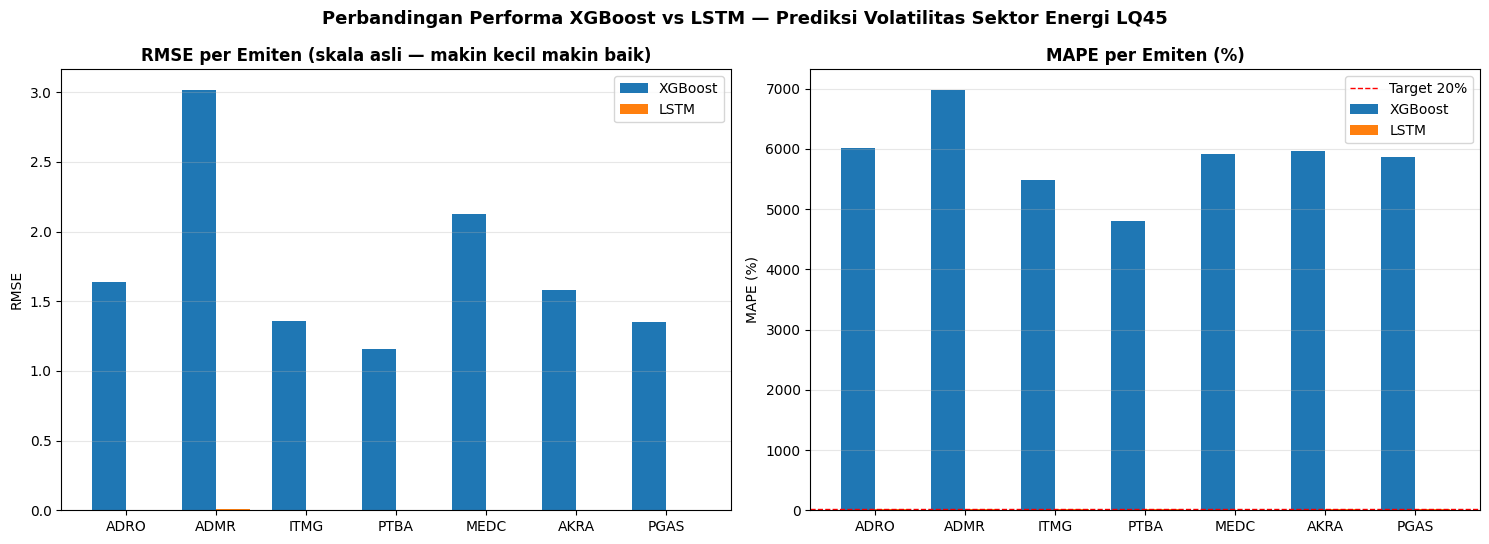

  💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_perbandingan_xgb_lstm.png


In [10]:
if len(emiten_eval):
    x_pos = np.arange(len(emiten_eval)); w = 0.38
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

    # RMSE
    ax[0].bar(x_pos - w/2, [hasil_xgb[e]['RMSE']  for e in emiten_eval], w, label='XGBoost')
    ax[0].bar(x_pos + w/2, [hasil_lstm[e]['RMSE'] for e in emiten_eval], w, label='LSTM')
    ax[0].set_title('RMSE per Emiten (skala asli — makin kecil makin baik)', fontweight='bold')
    ax[0].set_xticks(x_pos); ax[0].set_xticklabels(emiten_eval); ax[0].set_ylabel('RMSE')
    ax[0].legend(); ax[0].grid(axis='y', alpha=0.3)

    # MAPE
    ax[1].bar(x_pos - w/2, [hasil_xgb[e]['MAPE (%)']  for e in emiten_eval], w, label='XGBoost')
    ax[1].bar(x_pos + w/2, [hasil_lstm[e]['MAPE (%)'] for e in emiten_eval], w, label='LSTM')
    ax[1].axhline(20, ls='--', lw=1, color='red', label='Target 20%')
    ax[1].set_title('MAPE per Emiten (%)', fontweight='bold')
    ax[1].set_xticks(x_pos); ax[1].set_xticklabels(emiten_eval); ax[1].set_ylabel('MAPE (%)')
    ax[1].legend(); ax[1].grid(axis='y', alpha=0.3)

    plt.suptitle('Perbandingan Performa XGBoost vs LSTM — Prediksi Volatilitas Sektor Energi LQ45',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    path_fig = DIR_GAMBAR / 'gambar_perbandingan_xgb_lstm.png'
    plt.savefig(path_fig, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  💾 Gambar disimpan: {path_fig}')
else:
    print('  ⚠️  Tidak ada emiten untuk divisualisasikan.')


## 🏁 CELL 8 — Kesimpulan (menjawab RM-3)

In [11]:
if len(df_cmp) > 1:
    df_emiten = df_cmp[df_cmp['Emiten'] != 'RATA-RATA']
    n_lstm = (df_emiten['Model Terbaik'] == 'LSTM').sum()
    n_xgb  = (df_emiten['Model Terbaik'] == 'XGBoost').sum()
    avg_row = df_cmp[df_cmp['Emiten'] == 'RATA-RATA'].iloc[0]
    pemenang = avg_row['Model Terbaik']

    print('='*65)
    print('  🏁 KESIMPULAN PERBANDINGAN (RM-3)')
    print('='*65)
    print(f"  Menang per emiten (RMSE) : LSTM {n_lstm}/{len(df_emiten)} | "
          f"XGBoost {n_xgb}/{len(df_emiten)}")
    print(f"  Rata-rata RMSE  : XGBoost={avg_row['RMSE_XGB']:.5f} | LSTM={avg_row['RMSE_LSTM']:.5f}")
    print(f"  Rata-rata MAPE  : XGBoost={avg_row['MAPE_XGB(%)']:.2f}% | LSTM={avg_row['MAPE_LSTM(%)']:.2f}%")
    print(f"  Rata-rata R2    : XGBoost={avg_row['R2_XGB']:.4f} | LSTM={avg_row['R2_LSTM']:.4f}")
    print()
    print(f"  ➤ Model terbaik secara keseluruhan: **{pemenang}**")
    print('='*65)
else:
    print('  ⚠️  Data perbandingan belum lengkap — pastikan kedua model & data uji tersedia.')


  🏁 KESIMPULAN PERBANDINGAN (RM-3)
  Menang per emiten (RMSE) : LSTM 7/7 | XGBoost 0/7
  Rata-rata RMSE  : XGBoost=1.74811 | LSTM=0.00491
  Rata-rata MAPE  : XGBoost=5857.64% | LSTM=16.52%
  Rata-rata R2    : XGBoost=-41584.2062 | LSTM=0.6686

  ➤ Model terbaik secara keseluruhan: **LSTM**
